# ==============================================
# 05_Explainability_SHAP_PDP.ipynb
# ==============================================

Train shape: (754, 18), Test shape: (27, 18)


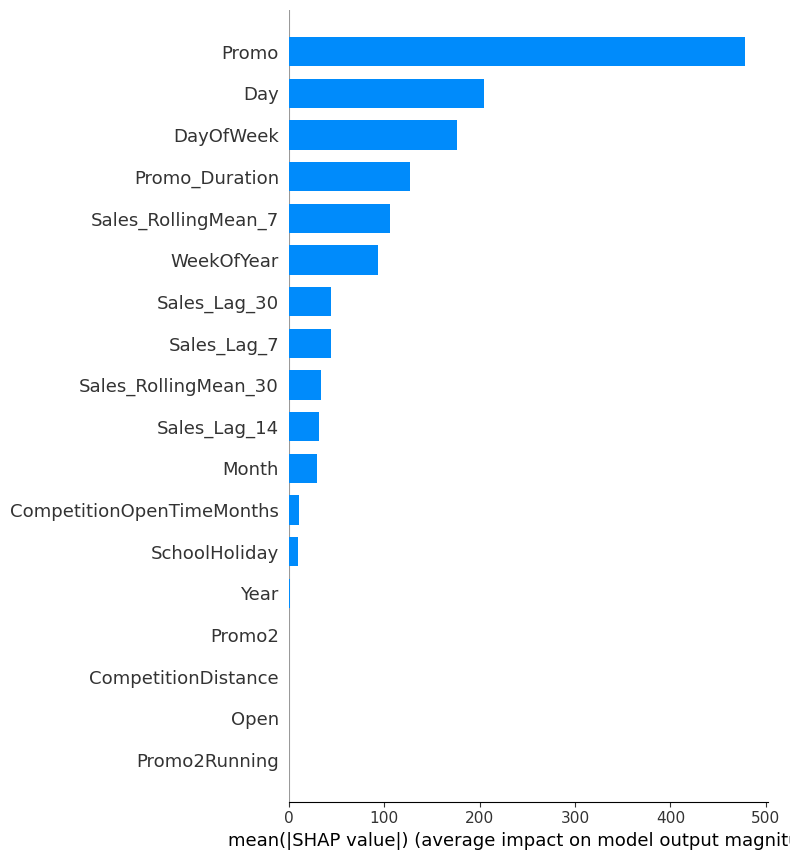

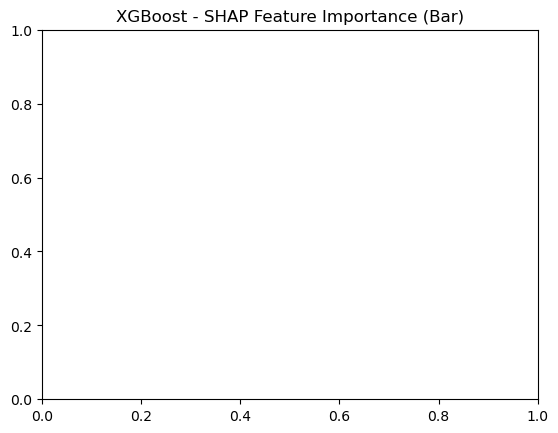

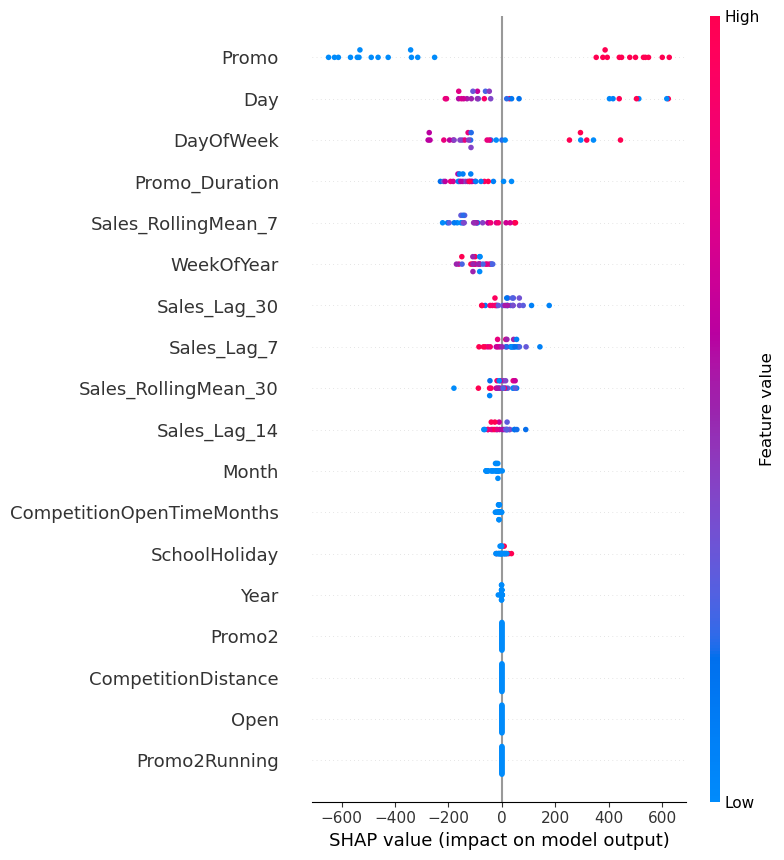

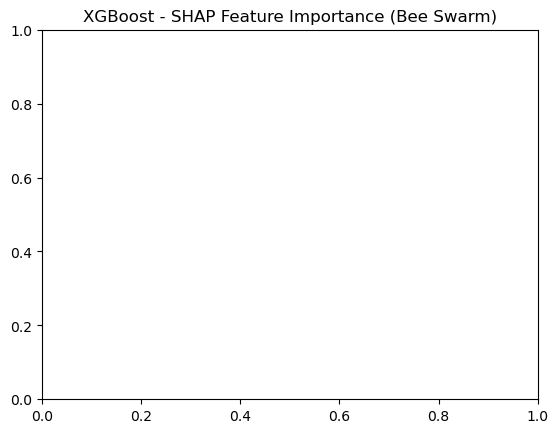

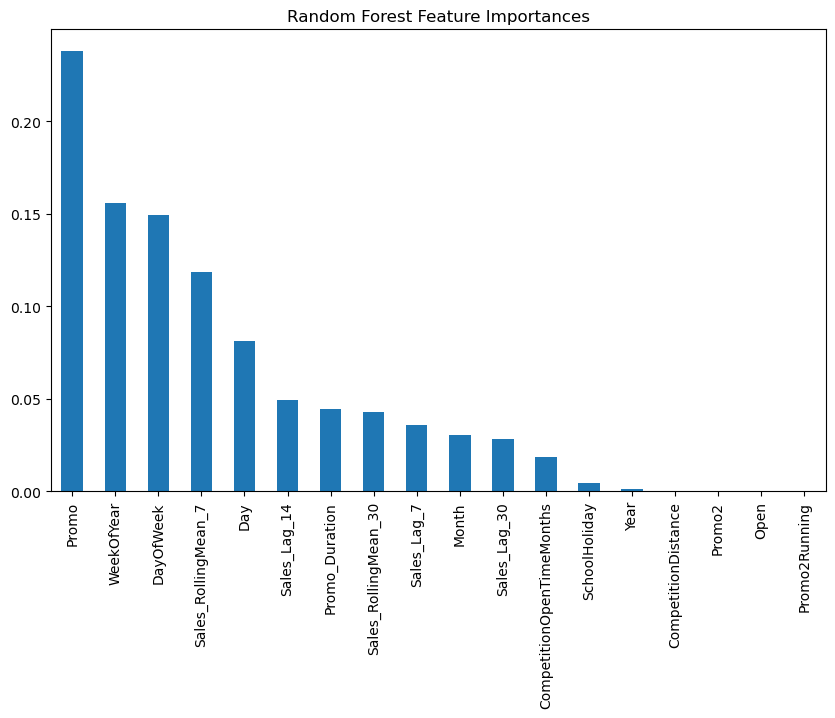

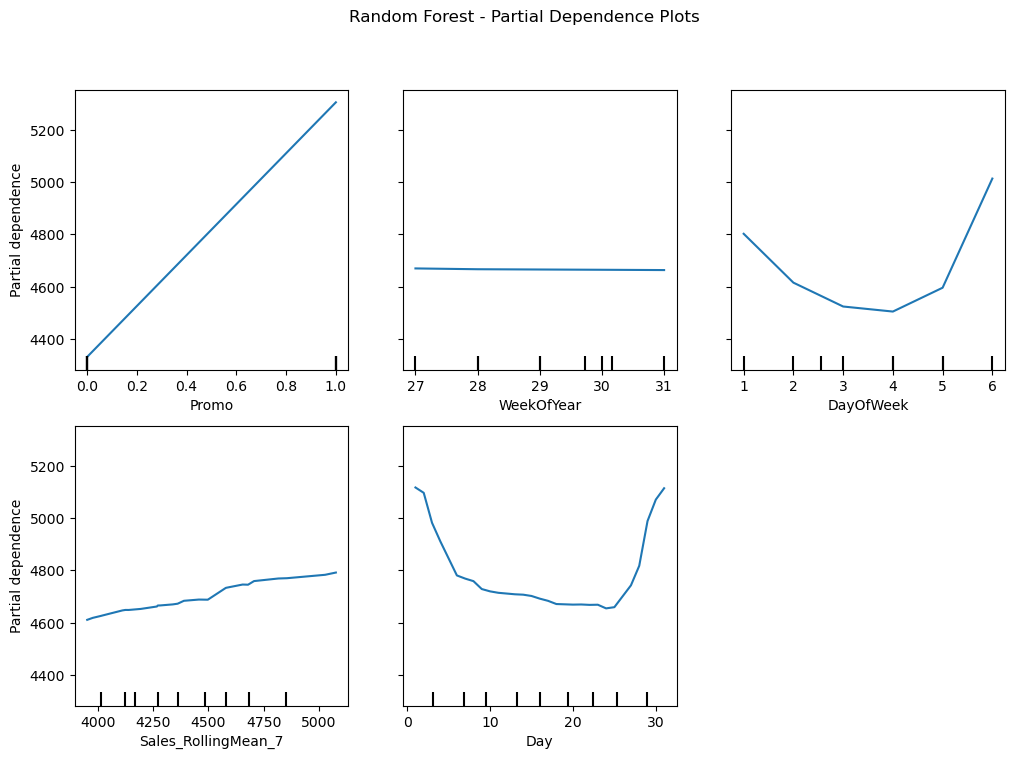

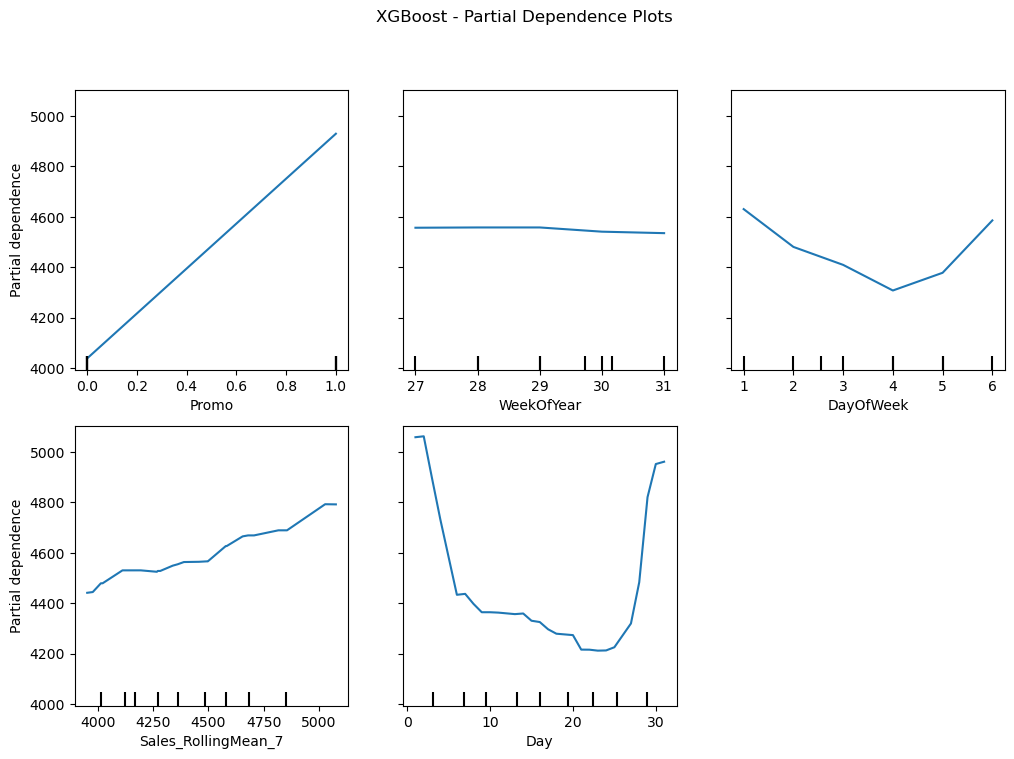

In [3]:
# ==============================================
# 05_Explainability_SHAP_PDP.ipynb
# ==============================================

# 1. Install if needed
# pip install shap
# pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib  # For loading saved models if needed
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.inspection import PartialDependenceDisplay

import warnings
warnings.filterwarnings('ignore')

# 2. Load Feature-Engineered Data
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/rossmann_forecasting/data/feature_engineered_rossmann.csv', parse_dates=['Date'])
store_id = 1
df_store = df[df['Store'] == store_id].copy()

# 3. Prepare Data
features = df_store.drop(columns=['Sales', 'Customers', 'Date', 'Store', 'PromoInterval'])
target = df_store['Sales']

# Train/Test Split
X_train = features[df_store['Date'] < '2015-07-01']
X_test = features[df_store['Date'] >= '2015-07-01']
# Keep only numeric features (drop any object columns)
X_train = X_train.select_dtypes(include=[np.number])
X_test = X_test.select_dtypes(include=[np.number])

y_train = target[df_store['Date'] < '2015-07-01']
y_test = target[df_store['Date'] >= '2015-07-01']

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# 4. Train or Load Models

# Re-train if needed (same as 03_MLModels notebook)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

xgb_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)

# 5. SHAP Explainability for XGBoost

# Initialize SHAP explainer
explainer = shap.Explainer(xgb_model, X_train)
shap_values = explainer(X_test)

# 6. SHAP Summary Plot
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)
plt.title('XGBoost - SHAP Feature Importance (Bar)')
plt.show()

shap.summary_plot(shap_values, X_test, show=True)
plt.title('XGBoost - SHAP Feature Importance (Bee Swarm)')
plt.show()

# 7. Random Forest Feature Importances
importances_rf = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances_rf = importances_rf.sort_values(ascending=False)

plt.figure(figsize=(10,6))
importances_rf.head(20).plot(kind='bar')
plt.title('Random Forest Feature Importances')
plt.show()

# 8. Partial Dependence Plots (PDP)

# Pick top features manually or from SHAP / RF importances
top_features = importances_rf.head(5).index.tolist()

# PDP for Random Forest
fig, ax = plt.subplots(figsize=(12,8))
PartialDependenceDisplay.from_estimator(rf_model, X_test, features=top_features, ax=ax)
plt.suptitle('Random Forest - Partial Dependence Plots')
plt.show()

# PDP for XGBoost (optional)
fig, ax = plt.subplots(figsize=(12,8))
PartialDependenceDisplay.from_estimator(xgb_model, X_test, features=top_features, ax=ax)
plt.suptitle('XGBoost - Partial Dependence Plots')
plt.show()
